# Lab 5: Detecting Exoplanet Transits

## Tutorial 1: Data Cleaning, Image Tracking and Aperture Photometry

For this tutorial, I will introduce you to the dataset from the William Hershel Telescope and I will take you through the initial data cleaning process. 

This lab builds upon several data analysis methods that we have seen in previous labs. I am going to assume that you already understand these concepts for this tutorial. If you would like me to describe any of the following concepts in more detail, please let me know or come to office hours:

- Downloading the data.
- Working with darkes, darks, and flats (ignore the files with the wrong sized images).
- Finding/Centroiding stars on a CCD
- The basics of Aperture Photometry

# The Goal of this Lab

We are trying to determine a decrease in a star's flux resulting from the transit of an exoplanet orbiting the star. This means that we will need to compute the flux of our target and eliminate all other sources of flux variation that are not the exoplanet transit. We will do this through so-called "Reference Stars".

# Mapping Reference Stars

What is a reference star? 

A reference star is a star that will be used to remove the image-to-image variation of the brightness of our target star. This variation is considerably larger than the variation cause by the transit of the exoplanet. The way I think about it is as follows:

$$ \bar{I(t)} = f(t) I(t) $$

Where $I(t)$ is the true light curve of a star, $\bar{I(t)}$ is or measured light curve and $f(t)$ is a systematic (fractional) variation experienced by all stars. That is to say, we are assuming that there existing a global scalar which affects all stars in a particular image. To be precise, we are saying that between the images there is an environmental change (likely atmosphere related) which can block a consistent fraction of all photons across the image (for example, as the telescope points closer to the horizon we expect more photons will be blocked by the atmopshere due to the increased air mass).

Our goal is then to measure the function $f(t)$ in order to remove it from the data. If we assume that the $f(t)$ is the same for all stars, we can use any other star in the image in order to compute it, assuming that the true light curve of that star is constant. The quality of a reference star is then determined by how closely it meets that constraint. Many stars will not meet this constraint due to their instrinsic variability. The more and higher quality reference stars we use, the better our measurement of $f(t)$.

The easiest method to find good reference stars is to manually select stars with similar intensity to your target star that are not crowded (i.e. other stars will not interfere with their flux calculation). This actually be quite time consuming, and doesn't generalize. I will show you a few methods for automating this process.

The first major goal in this lab is to get positions of all of "reference" stars in each image so that we can easily compute the light curves for each of them. Here is a quick description of the problem at hand:

We need to find the positions of each reference star in each image, but the position of each star **changes across the image set**. We want to do this for as many stars as possible.
    
Let's start by look at the data!

#Target Files: 364, #Dark Files: 26, #Flat Files: 47
DATE AND TIME OF OBSERVATION: 2011-05-22
APPROXIMATE CENTER OF THE OBSERVING FIELD (RA/DEC): [' 17:15:21.311', '+04:56:22.37']


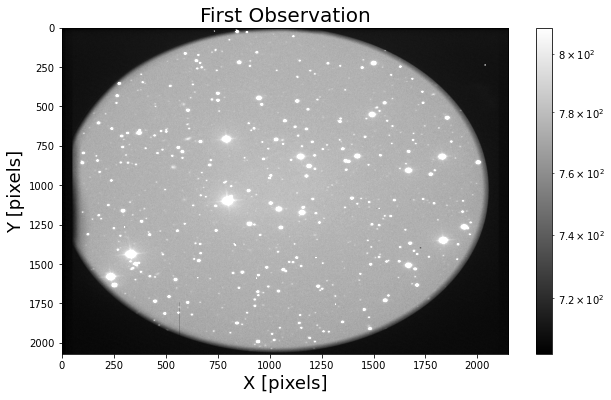

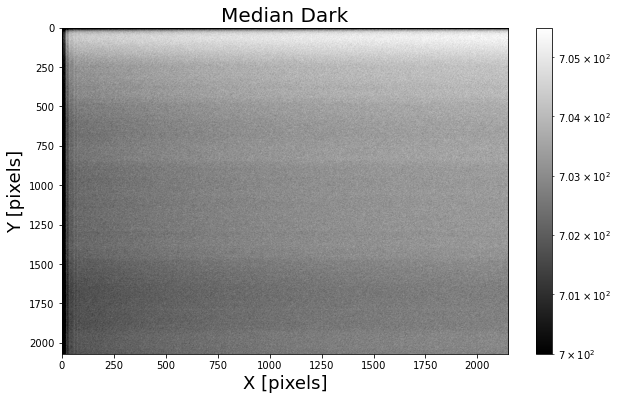

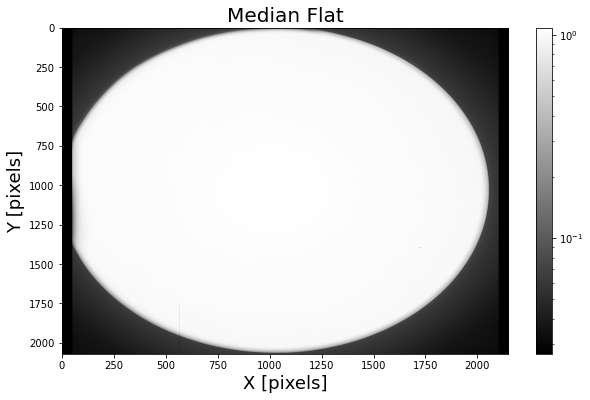

In [1]:
import numpy as np
import ta_funcs_transit as ta
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import clear_output

def sort_files(all_files):
    
    #Get only the fits files
    fits_files = [f for f in all_files if '.fit' in f]
    
    #Extract the observation number from the filename
    file_nums = [int(f[1:8]) for f in fits_files]
    
    #Sort them into groups
    dark_files_1 = [fits_files[i] for i in range(len(fits_files))\
                  if file_nums[i] >= 1599995 and file_nums[i] <= 1600020]
    flat_files_1 = [fits_files[i] for i in range(len(fits_files))\
                  if file_nums[i] >= 1598072 and file_nums[i] <= 1598089]
    flat_files_2 = [fits_files[i] for i in range(len(fits_files))\
                  if file_nums[i] >= 1599966 and file_nums[i] <= 1599994]
    target_files = [fits_files[i] for i in range(len(fits_files))\
                  if file_nums[i] >= 1599579 and file_nums[i] <= 1599942]
    
    #Combine the flats together
    flat_files_1.extend(flat_files_2)
    
    #Sort the targets into observation order
    target_files.sort()

    #Add folder back to the path to get the full path
    target_files = [folder + f for f in target_files]
    dark_files_1 = [folder + f for f in dark_files_1]
    flat_files_1 = [folder + f for f in flat_files_1]
    
    return target_files, dark_files_1, flat_files_1

folder = "/home/jacob/AST325/AST325-Lab5/Lab5_ACAM_DATA/"

target_files, dark_files, flat_files = sort_files(ta.get_all_files(folder))

print(f"#Target Files: {len(target_files)}, #Dark Files: {len(dark_files)}, #Flat Files: {len(flat_files)}")

header, first_image, cof = ta.read_file(target_files[0], 
                                        folder='', 
                                        sky_image=True, 
                                        verbose=True)
ta.plot_image(first_image, title = "First Observation", log = True)

# dark = ta.get_dark_from_files(dark_files, shape = first_image.shape)
# flat = ta.get_flat_from_files(flat_files, shape = first_image.shape)

# np.save("dark", dark)
# np.save("flat", flat)

dark = np.load("dark.npy")
flat = np.load("flat.npy")

ta.plot_image(dark, title = "Median Dark", log = True)
ta.plot_image(flat, title = "Median Flat", log = True)

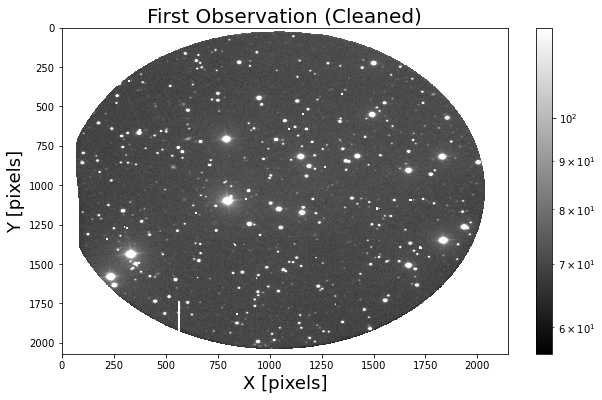

In [2]:
first_image_cleaned = ta.clean_image(first_image, dark, flat)
#Remove Vignette
first_image_cleaned[flat < 0.6] = np.nan
ta.plot_image(first_image_cleaned, title = "First Observation (Cleaned)", log = True)

In [3]:
from IPython.display import Video

Video("lab5-data.mp4")

In this video, we can clearly see the overall brightness of the image increasing and decreasing. If you look closely, you can also see the stars moving with some small jumps throughout the dataset. 

To get our reference light curves, we will need to identify where the star is in each image so that we can put down our apertures and get a flux measurement. One way to do this is to use the plate solution of each image and then identify the RA/DEC coordinates of each star, and then use the plate solution in order to track the stars. However, the data does not have the plate solution in the FITS header. Here I will should you a simplified way to track our stars without using astropy.

Our approach will be to track the motion of one star and assume that the motion of all other stars is the exact same.

In [53]:
#Read through all of the files:
x, y = [1130,470] #A starting location near an isolated star
boxsize = 20 #Box radius

obs_cube = np.empty([len(target_files), boxsize*2+1, boxsize*2+1])
centroids = np.empty([len(target_files), 2])

for i, f in enumerate(target_files):
    #Open the file
    header, im, cof = ta.read_file(f, 
                                        folder='', 
                                        sky_image=True, 
                                        verbose=False)
    #Clean the observation
    im = ta.clean_image(im, dark, flat)

    #Make a box around the isolated star:
    box = im[y-boxsize: y+boxsize+1, 
             x-boxsize: x+boxsize+1].copy()
    
    #Find the centroid of the star within that box
    centroids[i] =  ta.centroid(box)

    #Save the box
    obs_cube[i] = box


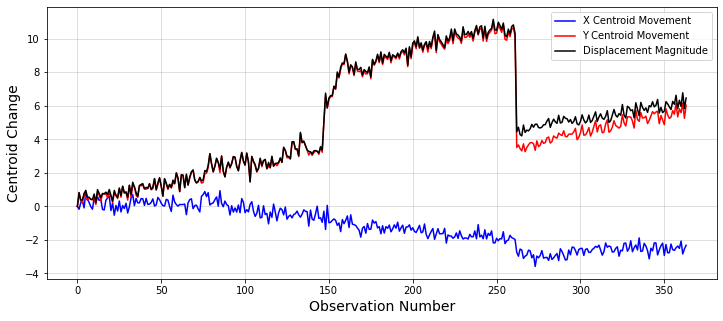

In [54]:
#Now we can compute the centroid motion vector across the entrie set for this one star
movement_vectors = np.array([centroids[i] - centroids[0] for i in range(centroids.shape[0])])
plt.figure(figsize=(12,5))
plt.plot(np.arange(movement_vectors.shape[0]), movement_vectors[:,0], 
         label = 'X Centroid Movement', 
         color = 'blue')
plt.plot(np.arange(movement_vectors.shape[0]), movement_vectors[:,1], 
         label = 'Y Centroid Movement',
         color = 'r')
plt.plot(np.arange(movement_vectors.shape[0]), np.sqrt(movement_vectors[:,0]**2 + movement_vectors[:,1]**2), 
         label = 'Displacement Magnitude',
         color = 'k')
plt.xlabel("Observation Number", size = 14)
plt.ylabel("Centroid Change", size = 14)
plt.grid(alpha = 0.5)
plt.legend()
plt.show()

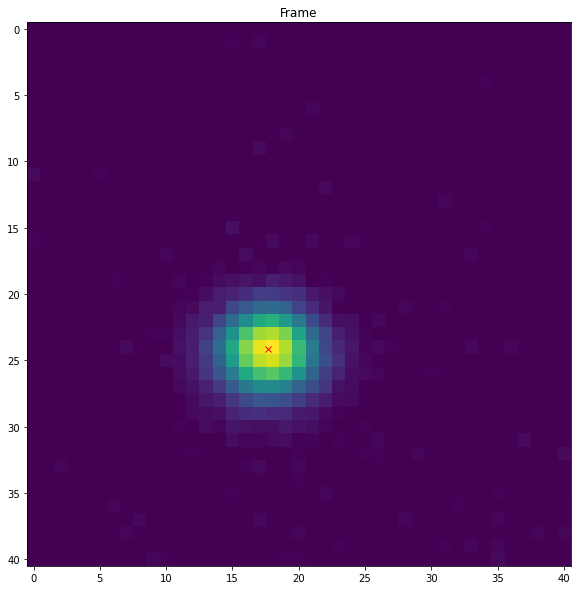

In [57]:
#here I am plotting the region where the star jumps to see that my code is working well
ta.plot_tracking(obs_cube[250:], centroids[250:], NUM_FRAMES_TO_WATCH=100)

So we have now tracked one star across the image, lets see how that motion translates to a new field of stars

In [58]:
#Read through all of the files:
x, y = [1277, 229] #Choose a new star

boxsize = 20
new_obs_cube = np.empty([len(target_files), boxsize*2+1, boxsize*2+1])
new_centroids = np.empty_like(centroids)

for i, f in enumerate(target_files):

    #Apply our centroid motion vectors to the box position
    tracked_x, tracked_y = int(np.round(x + movement_vectors[i,0],0)), int(np.round(y + movement_vectors[i,1],0))

    #Open the file
    header, im, cof = ta.read_file(f, 
                                        folder='', 
                                        sky_image=True, 
                                        verbose=False)
    #Clean the observation
    im = ta.clean_image(im, dark, flat)

    #Make a box in the same area:
    box = im[tracked_y-boxsize: tracked_y+boxsize+1, 
             tracked_x-boxsize: tracked_x+boxsize+1].copy()

    #Find the centroid of the star within that box
    new_centroids[i] =  ta.centroid(box)

    #Save the box
    new_obs_cube[i] = box



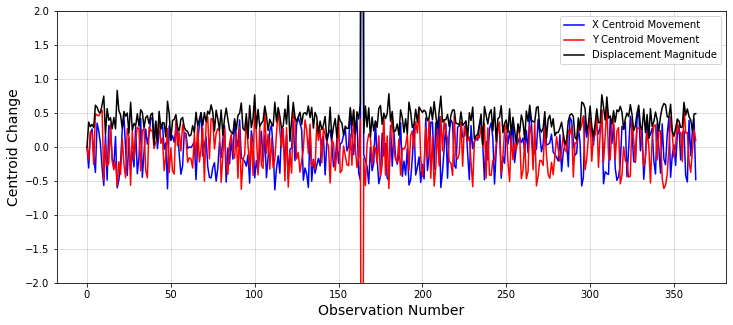

In [8]:
#Now we can compute the centroid motion vector across the entrie set for this one star
new_movement_vectors = np.array([new_centroids[i] - new_centroids[0] for i in range(new_centroids.shape[0])])
plt.figure(figsize=(12,5))
plt.plot(np.arange(new_movement_vectors.shape[0]), new_movement_vectors[:,0], 
         label = 'X Centroid Movement', 
         color = 'blue')
plt.plot(np.arange(new_movement_vectors.shape[0]), new_movement_vectors[:,1], 
         label = 'Y Centroid Movement',
         color = 'r')
plt.plot(np.arange(new_movement_vectors.shape[0]), np.sqrt(new_movement_vectors[:,0]**2 + new_movement_vectors[:,1]**2), 
         label = 'Displacement Magnitude',
         color = 'k')
plt.xlabel("Observation Number", size = 14)
plt.ylabel("Centroid Change", size = 14)
plt.grid(alpha = 0.5)
plt.ylim(-2,2)
plt.legend()
plt.show()

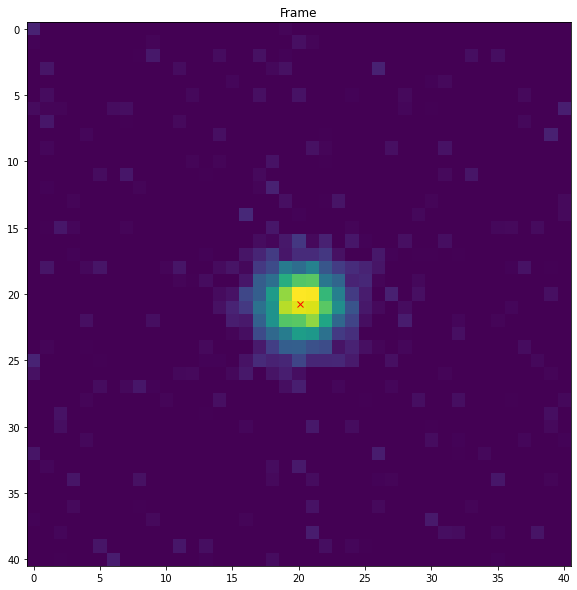

In [59]:
#Let's see how well it worked!, there shouldn't be any jump
ta.plot_tracking(new_obs_cube[250:], new_centroids[250:], NUM_FRAMES_TO_WATCH=400)

So we can see that the star movement went down from ~10 pixels down to less that 1 pixel. Good enough for our purposes!

Lastly, we can look at Aperture Photometry. This should be entirely a review from Lab 3:

For aperture photometry, there are three radii you need to choose. Lets call them $R_{aperture}$, $R_{inner}$, $R_{outer}$. The purpose of $R_{aperture}$ is to encompass as much of the starlight as possible but not be so big as to add additional noise to the measurments. The purpose of $R_{inner}$ and $R_{outer}$ is to define a localized region around the star that measures estimate the local background flux, $F_{bg}$.

The proper way to choose these values is by formulating and maximizing the signal-to-noise ratio. For this lab, it should be sufficient to choose an aperture and annulus size such that $R_{aperture}$ is roughly three ot four times the radius of the point spread function (where the radius is the standard deviation of a best-fit Gaussian). There aren't many stars nearby the reference stars, so there is a lot of freedom on the size of the annulus.

The total flux, $F_{star}$ is the sum of all of the pixels in the aperture minus the contribution from the background. We can use the annulus pixels to estimate the local background intensity:

$$I_{bg} = \sum_{annulus} \frac{I(x,y)}{N_{annulus}}$$

where $N_{annulus}$ is the number of pixels in the annulus. Now we can estimate the star flux:

$$F_{star} = \sum_{aperture}( I(x,y) - I_{bg})$$


I have used this source for computing the error in my fluxes: https://wise2.ipac.caltech.edu/staff/fmasci/ApPhotUncert.pdf

For my implementation, I get the following formula:

$$\Delta F = \sqrt{\frac{F}{g} + N_{aperture}\left(1 + \frac{\pi}{2}\frac{N_{aperture}}{N_{annulus}}\right)\sigma_{bg}^2}$$

Where here I have assumed that read noise is negligeable and that there are no large pixel-to-pixel correlations in the image.

I am going to use a gain of 1.16 electrons/ADU which I found here:  https://www.ing.iac.es/Astronomy/telescopes/wht/fitsheader_acamsc_raw.html

For this lab, let's look at how you can optimize your aperture radius to get the best Signal-to-Noise Ratio!


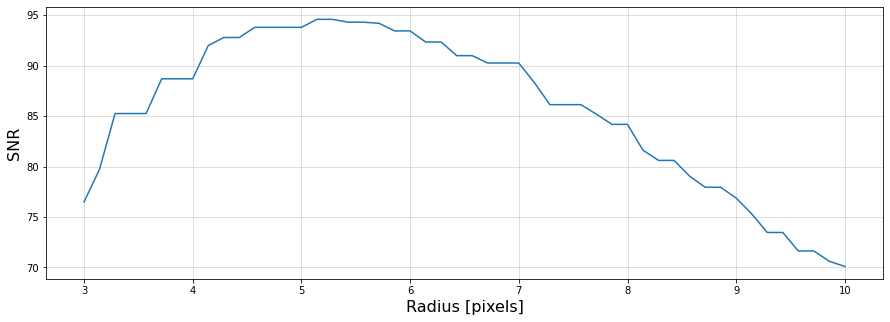

In [63]:
#Find optimal Aperture
radii = np.linspace(3,10)
snr = np.empty_like(radii)
GAIN = 1.16
annulus = ta.get_annulus(new_obs_cube[0].shape,15,18)
for i, r in enumerate(radii):
    aperture = ta.get_aperture(new_obs_cube[0].shape, r) #I picked kinda random numbers here
    f, f_err = ta.get_flux(new_obs_cube[0], aperture, annulus, gain = GAIN)
    snr[i] = f/f_err
plt.figure(figsize=(15,5))
plt.plot(radii, snr)
plt.grid(alpha=0.5)
plt.xlabel("Radius [pixels]", size = 16)
plt.ylabel("SNR", size = 16)
plt.show()

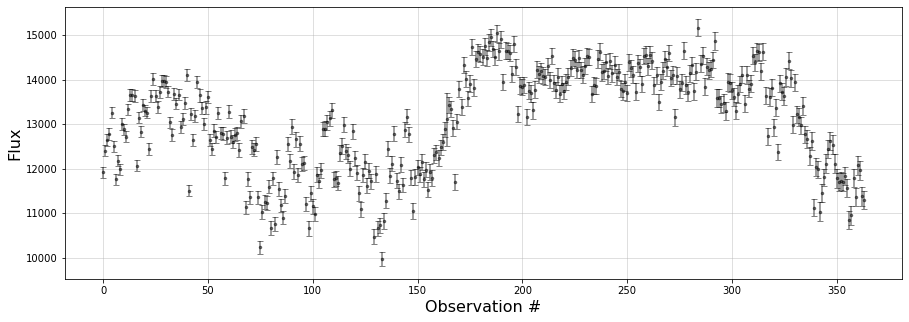

In [67]:
#Let's see what happens to our noise when I change the apertures!

aperture = ta.get_aperture(new_obs_cube[0].shape, 5.5) 
annulus = ta.get_annulus(new_obs_cube[0].shape,12,18)
GAIN = 1.16
fluxes, fluxes_err = np.zeros(len(new_obs_cube)), np.zeros(len(new_obs_cube))
for i, obs in enumerate(new_obs_cube):
    fluxes[i], fluxes_err[i] = ta.get_flux(obs, aperture, annulus, gain = GAIN)

plt.figure(figsize=(15,5))
plt.errorbar(np.arange(fluxes.shape[0]), fluxes, yerr=fluxes_err, fmt = '.',ms = 5, capsize=3, color = 'k', alpha = 0.5)
plt.grid(alpha=0.5)
plt.xlabel("Observation #", size = 16)
plt.ylabel("Flux", size = 16)
plt.show()

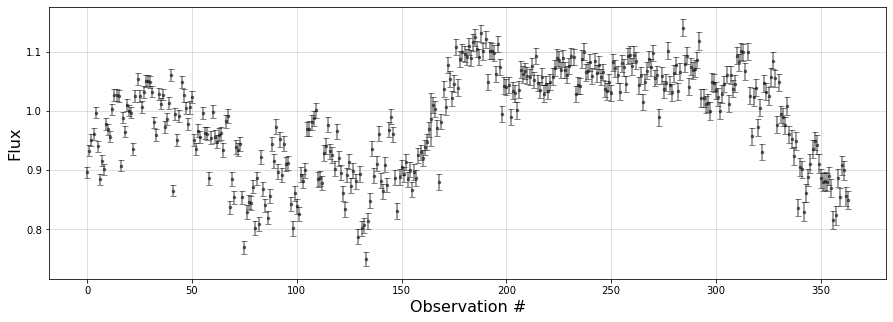

In [69]:
plt.figure(figsize=(15,5))
plt.errorbar(np.arange(fluxes.shape[0]), fluxes/np.median(fluxes), yerr=fluxes_err/np.median(fluxes), fmt = '.',ms = 5, capsize=3, color = 'k', alpha = 0.5)
plt.grid(alpha=0.5)
plt.xlabel("Observation #", size = 16)
plt.ylabel("Flux", size = 16)
plt.show()